In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Part A: Load & Explore

In [ ]:
ratings_df=pd.read_csv("ratings.csv") 
movies_df=pd.read_csv("movies.csv")

In [7]:
numberofusers=ratings_df["userId"].nunique()
numberofmovies=ratings_df["movieId"].nunique()
numberofratings = len(ratings_df)

total = numberofmovies*numberofusers
missing = total-numberofratings
sparsity= missing/total

print("Number of users:", numberofusers)
print("Number of movies:", numberofmovies)
print("Number of ratings:",numberofratings)
print("Sparsity:", f"{sparsity:.2%}")

Number of users: 610
Number of movies: 9724
Number of ratings: 100836
Sparsity: 98.30%


In [8]:
ratingmatrix=ratings_df.pivot_table(index="userId",columns="movieId",values="rating")
ratingmatrix

movieId,1,2,3,4,5,6,7,8,9,10,...,193565,193567,193571,193573,193579,193581,193583,193585,193587,193609
userId,,,,,,,,,,,,,,,,,,,,,
1,4.0,NaN,4.0,NaN,NaN,4.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
606,2.5,NaN,NaN,NaN,NaN,NaN,2.5,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
607,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
608,2.5,2.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,4.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


rating
0.5     1370
1.0     2811
1.5     1791
2.0     7551
2.5     5550
3.0    20047
3.5    13136
4.0    26818
4.5     8551
5.0    13211
Name: count, dtype: int64


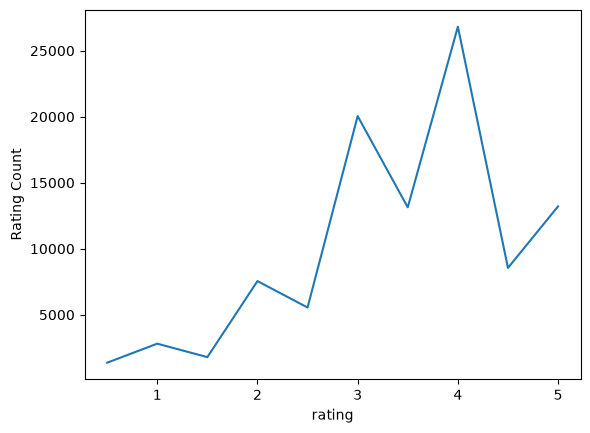

In [9]:
ratingcounts = ratings_df["rating"].value_counts().sort_index()
print(ratingcounts)
ratingcounts.plot()
plt.ylabel("Rating Count")
plt.show()

userId
1       232
2        29
3        39
4       216
5        44
       ... 
606    1115
607     187
608     831
609      37
610    1302
Length: 610, dtype: int64


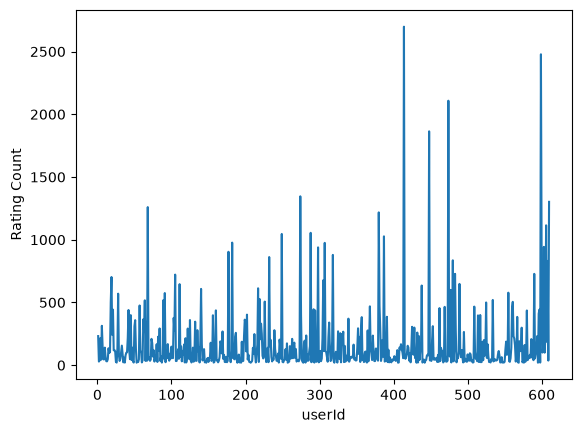

In [10]:
ratings_per_user = ratings_df.groupby("userId").size()
print(ratings_per_user)
ratings_per_user.plot()
plt.ylabel("Rating Count")
plt.show()

## Part B: Similarity Metrics

In [11]:
def get_co_rated(matrix, a, b, axis):

    if axis == "columns":
        vec1 = matrix.loc[:,a]
        vec2 = matrix.loc[:,b]

    elif axis == "index":
        vec1 = matrix.loc[a]
        vec2 = matrix.loc[b]

    mask = vec1.notna() & vec2.notna()

    return vec1[mask].values , vec2[mask].values

In [12]:
def euclidean_similarity(vec1, vec2):
    distance = np.sqrt(np.sum((vec1 - vec2) ** 2))
    similarity=1/(1 + distance)
    return similarity

In [13]:
def cosine_similarity(vec1, vec2):
    dot_product =np.dot(vec1, vec2)
    vec1_magnitude=np.sqrt(np.sum(vec1**2))
    vec2_magnitude=np.sqrt(np.sum(vec2**2)) 
    if vec1_magnitude == 0 or vec2_magnitude == 0:
        return 0
    similarity =dot_product/(vec1_magnitude*vec2_magnitude)
    return similarity
vec1 = np.array([5, 4, 5, 3])
vec2 = np.array([3, 2, 3, 1])

print(cosine_similarity(vec1, vec2))

0.9871639953033075


In [14]:
def pearson_similarity(vec1, vec2):
    vec1_mean=np.mean(vec1)
    vec2_mean=np.mean(vec2)

    vec1_centered=vec1-vec1_mean
    vec2_centered=vec2-vec2_mean

    similarity=cosine_similarity(vec1_centered,vec2_centered)

    return similarity
vec1 = np.array([5, 4, 5, 3])
vec2 = np.array([3, 2, 3, 1])

print(pearson_similarity(vec1, vec2))

1.0


In [15]:
nearest_users_cache={}
nearest_items_cache={}

## Part C: User-Based Collaborative Filtering

In [16]:
def find_k_nearest_users(matrix , target_user , k, similarity_fun):
    cache_key=(id(matrix),target_user,similarity_fun)
    if cache_key not in nearest_users_cache:
        similarities=[]
        for other_users in matrix.index:
            if other_users==target_user:
                continue

            v1, v2= get_co_rated(matrix, target_user, other_users, axis='index')
            if len(v1)<2:
                continue

            sim=similarity_fun(v1,v2)
            if sim is not None and not np.isnan(sim):
                similarities.append((other_users, sim))

        similarities.sort(key=lambda x: x[1], reverse=True)
        nearest_users_cache[cache_key] = similarities
    return nearest_users_cache[cache_key][:k]

In [17]:
def user_based_prediction(matrix, target_user, target_item, k, similarity_fun):
    neighbors=find_k_nearest_users(matrix,target_user,k,similarity_fun)
    num=0.0
    den=0.0

    for neighbor_id,sim in neighbors:
        rating=matrix.loc[neighbor_id,target_item]

        if not np.isnan(rating):
            num+=sim*rating
            den+=abs(sim)

    if den==0:
        return None
    return num/den

## Part D: Item-Based Collaborative Filtering

In [18]:
def find_k_nearest_items(matrix, target_item,k, similarity_fn):
    cache_key=(id(matrix),target_item,similarity_fn)
    if cache_key not in nearest_items_cache:
        similarities=[]
        for other_items in matrix.columns:
            if other_items==target_item:
                continue

            v1,v2=get_co_rated(matrix, other_items, target_item, axis='columns')
            if len(v1)<2:
                continue
            sim=similarity_fn(v1,v2)
            if sim is not None and not np.isnan(sim):
                similarities.append((other_items, sim))
                
        similarities.sort(key=lambda x: x[1], reverse=True)
        nearest_items_cache[cache_key]=similarities
    return nearest_items_cache[cache_key][:k]

In [19]:
def predict_rating_item_based(matrix, target_user, target_item, k, similarity_fn):
    neighbors = find_k_nearest_items(matrix, target_item, k, similarity_fn)
    
    num = 0.0
    den = 0.0
    
    for neighbor_item, sim in neighbors:
        rating = matrix.loc[target_user, neighbor_item]
        if not np.isnan(rating):
            num += sim * rating
            den += abs(sim)
            
    if den == 0:
        return None
        
    return num / den

## Part E: Evaluation

In [20]:
def train_test_split_ratings(ratings_df, test_fraction=0.2):
    train_parts = []
    test_parts = []

    for user_id, user_ratings in ratings_df.groupby("userId"):
        test = user_ratings.sample(
            frac=test_fraction,
            random_state=42
        )
        train = user_ratings.drop(test.index)

        train_parts.append(train)
        test_parts.append(test)

    train_df = pd.concat(train_parts)
    test_df = pd.concat(test_parts)

    return train_df, test_df

In [21]:
train_df, test_df = train_test_split_ratings(ratings_df)

print("Original ratings:", len(ratings_df))
print("Training ratings:", len(train_df))
print("Testing ratings:", len(test_df))
print("Test fraction:", len(test_df) / len(ratings_df))

Original ratings: 100836
Training ratings: 80672
Testing ratings: 20164
Test fraction: 0.19996826530207465


In [22]:
train_matrix = train_df.pivot_table(
    index="userId",
    columns="movieId",
    values="rating"
)

print("Training matrix shape:", train_matrix.shape)
print("Users:", train_matrix.index.nunique())
print("Movies:", train_matrix.columns.nunique())
print("Missing values:", train_matrix.isna().sum().sum())

Training matrix shape: (610, 8970)
Users: 610
Movies: 8970
Missing values: 5391028


In [23]:
def evaluate(train_matrix, test_df, k, similarity_fun, method):
    actual_ratings = []
    predicted_ratings = []
    failed = 0

    for _, row in test_df.iterrows():
        user_id = row["userId"]
        movie_id = row["movieId"]
        actual_rating = row["rating"]

        if movie_id not in train_matrix.columns:
            failed += 1
            continue

        if method == "user":
            prediction = user_based_prediction(
                train_matrix, user_id, movie_id, k, similarity_fun
            )
        elif method == "item":
            prediction = predict_rating_item_based(
                train_matrix, user_id, movie_id, k, similarity_fun
            )
        else:
            raise ValueError("method must be 'user' or 'item'")

        if prediction is None or not np.isfinite(prediction):
            failed += 1
            continue

        actual_ratings.append(actual_rating)
        predicted_ratings.append(prediction)

    if len(actual_ratings) == 0:
        rmse = None
        mae = None
    else:
        errors = np.array(actual_ratings) - np.array(predicted_ratings)
        rmse = np.sqrt(np.mean(errors ** 2))
        mae = np.mean(np.abs(errors))

    failure_fraction = failed / len(test_df)

    return rmse, mae, failure_fraction

In [24]:
similarity_functions = {
    "Euclidean": euclidean_similarity,
    "Cosine": cosine_similarity,
    "Pearson": pearson_similarity
}

k_values = [5, 10, 20, 50]
methods = ["user", "item"]

results = []

for method in methods:
    for similarity_name, similarity_fun in similarity_functions.items():
        for k in k_values:
            print(
                f"Running: method={method}, "
                f"similarity={similarity_name}, k={k}"
            )

            rmse, mae, failure_fraction = evaluate(
                train_matrix,
                test_df,
                k,
                similarity_fun,
                method
            )

            results.append({
                "Method": method,
                "Similarity": similarity_name,
                "k": k,
                "RMSE": rmse,
                "MAE": mae,
                "Failure Fraction": failure_fraction
            })

results_df = pd.DataFrame(results)

print("\nAll experiments completed!")
display(results_df)

Running: method=user, similarity=Euclidean, k=5
Running: method=user, similarity=Euclidean, k=10
Running: method=user, similarity=Euclidean, k=20
Running: method=user, similarity=Euclidean, k=50
Running: method=user, similarity=Cosine, k=5
Running: method=user, similarity=Cosine, k=10
Running: method=user, similarity=Cosine, k=20
Running: method=user, similarity=Cosine, k=50
Running: method=user, similarity=Pearson, k=5
Running: method=user, similarity=Pearson, k=10
Running: method=user, similarity=Pearson, k=20
Running: method=user, similarity=Pearson, k=50
Running: method=item, similarity=Euclidean, k=5
Running: method=item, similarity=Euclidean, k=10
Running: method=item, similarity=Euclidean, k=20
Running: method=item, similarity=Euclidean, k=50
Running: method=item, similarity=Cosine, k=5
Running: method=item, similarity=Cosine, k=10
Running: method=item, similarity=Cosine, k=20
Running: method=item, similarity=Cosine, k=50
Running: method=item, similarity=Pearson, k=5
Running: me

,Method,Similarity,k,RMSE,MAE,Failure Fraction
0,user,Euclidean,5,1.182359,0.869622,0.908153
1,user,Euclidean,10,1.169835,0.858375,0.846657
2,user,Euclidean,20,1.163417,0.859300,0.761109
3,user,Euclidean,50,1.118214,0.831275,0.599732
4,user,Cosine,5,1.273007,0.941524,0.908203
5,user,Cosine,10,1.239184,0.915776,0.846707
6,user,Cosine,20,1.192889,0.891087,0.751885
7,user,Cosine,50,1.133175,0.848260,0.547957
8,user,Pearson,5,1.275733,0.947594,0.904235
9,user,Pearson,10,1.264846,0.951659,0.838475


## Part F: Analysis

 Question 16 :

 From my results, item-based Euclidean similarity with k=50 performed best and i also noticed that Item-based filtering generally had lower errors than user-based filtering. My initial expectation was different because Pearson worked better on a smaller example but Euclidean worked better on my dataset.  

Question 17: 

target user ([5,4,3,2]), User A ([4,3,2,1]), and User B ([5,4,2,2]).

The Euclidean similarity would be

-User a ---> 0.3333        -User b ---> 0.5 ,
so Euclidean ranks user b higher

The Pearson similarity would be 

-User a ---> 1        -User b ---> 0.946 ,
so Pearson ranks user a higher

Question 18

Item-based filtering is cheaper in this example because there are only 20,000 products compared with 200 million users. Comparing items involves far fewer entities than comparing users, making item-based filtering more practical to maintain in this situation.
